# ДЗ №2. Триаж

Предсказываю уровень ESI по данным первичного осмотра. Основная метрика — macro F1.

## Данные и валидация

### Загрузка данных с Kaggle

In [1]:
from pathlib import Path
import os
import zipfile

# Ноутбук можно запустить из своей папки или из корня репозитория
work = Path("s1/hw2") if Path("s1/hw2").is_dir() else Path(".")
data = work / "data"
files = ["train.csv", "test.csv", "sample_submission.csv"]
if not all((data / name).is_file() for name in files):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        if (folder / ".env").is_file():
            for line in (folder / ".env").read_text(encoding="utf-8").splitlines():
                if line.startswith("KAGGLE_API_TOKEN="):
                    os.environ.setdefault("KAGGLE_API_TOKEN", line.split("=", 1)[1].strip().strip(chr(34) + chr(39)))
            break
    from kaggle.api.kaggle_api_extended import KaggleApi

    data.mkdir(exist_ok=True)
    api = KaggleApi()
    api.authenticate()
    api.competition_download_files("triage", path=str(data), quiet=True)
    with zipfile.ZipFile(data / "triage.zip") as archive:
        for name in files:
            archive.extract(name, data)

print("Файлы данных:", ", ".join(files))

Файлы данных: train.csv, test.csv, sample_submission.csv


### Импорты и настройки

Для чистого окружения: 
```
%pip install pandas numpy matplotlib scikit-learn==1.8.0 optuna==5.1.0 lightgbm==4.7.0 catboost==1.2.10 kaggle
```

In [2]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import lightgbm as lgb
import optuna
import sklearn
from joblib import parallel_backend
from threadpoolctl import threadpool_limits
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, mean_absolute_error
from sklearn.model_selection import StratifiedKFold, cross_val_score, cross_validate, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 24)
plt.rcParams["figure.dpi"] = 100
optuna.logging.set_verbosity(optuna.logging.WARNING)
RANDOM_STATE = 42
LOGISTIC = "Logistic Regression"
TREE = "Decision Tree"
FOREST = "Random Forest"
BOOSTING = "Gradient Boosting"
names = [LOGISTIC, TREE, FOREST, BOOSTING]
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
print("scikit-learn", sklearn.__version__, "  Optuna", optuna.__version__, "  LightGBM", lgb.__version__)

scikit-learn 1.8.0   Optuna 5.1.0   LightGBM 4.7.0


### Выделение holdout

Откладываю 20% `train` до EDA и подбора параметров.

In [3]:
train = pd.read_csv(data / "train.csv")
test = pd.read_csv(data / "test.csv")
X = train.drop(columns=["id", "esi"])
y = train.esi
X_dev, X_hold, y_dev, y_hold = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
cat_cols = ["arrival_mode", "chief_complaint"]
num_cols = [c for c in X_dev if c not in cat_cols]
classes = np.arange(1, 6)

print("train:", train.shape, "  test:", test.shape)
print("Для экспериментов:", len(X_dev), "  отложено:", len(X_hold))

train: (8000, 18)   test: (5000, 17)
Для экспериментов: 6400   отложено: 1600


### Краткий EDA

In [4]:
print("Пропуски:", X_dev.isna().sum().sum(), "  повторы строк признаков:", X_dev.duplicated().sum())
print("Категорий:", X_dev[cat_cols].nunique().to_dict())
X_dev[num_cols].describe().T[["mean", "std", "min", "50%", "max"]].round(2)

Пропуски: 0   повторы строк признаков: 0
Категорий: {'arrival_mode': 3, 'chief_complaint': 26}


,mean,std,min,50%,max
age,43.01,17.68,18.0,42.00,98.0
heart_rate,82.44,13.82,40.0,82.00,160.0
sbp,124.63,16.89,50.0,125.00,179.0
dbp,78.50,11.66,25.0,79.00,119.0
mbp,93.83,12.89,35.0,94.40,134.8
resp_rate,16.37,3.19,7.0,16.00,31.0
spo2,97.37,2.32,60.0,98.00,99.0
temperature,36.86,0.63,33.2,36.80,39.6
gcs,14.85,1.08,3.0,15.00,15.0
pain_score,4.35,2.32,0.0,4.00,10.0


In [5]:
counts = y_dev.value_counts().sort_index()
class_balance = pd.DataFrame({
    "Класс": [f"ESI-{k}" for k in counts.index],
    "Число объектов": counts.to_numpy(),
    "Доля, %": (100 * counts / counts.sum()).to_numpy(),
})
class_balance.round(1)

,Класс,Число объектов,"Доля, %"
0,ESI-1,193,3.0
1,ESI-2,837,13.1
2,ESI-3,2409,37.6
3,ESI-4,2093,32.7
4,ESI-5,868,13.6


В каждом валидационном фолде около 39 пациентов с ESI-1. Сравниваю модели на одних и тех же фолдах.

Корреляции показателей давления:
      sbp   dbp   mbp
sbp  1.00  0.79  0.92
dbp  0.79  1.00  0.95
mbp  0.92  0.95  1.00


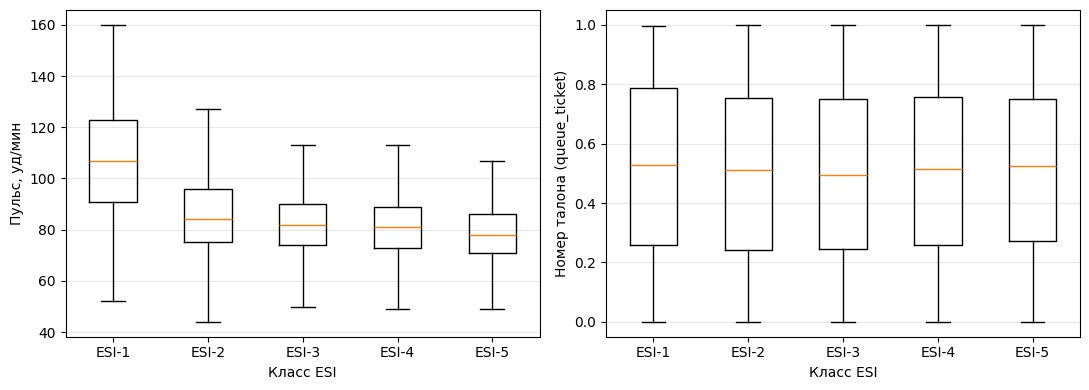

In [6]:
dev = X_dev.assign(esi=y_dev)
pressure = ["sbp", "dbp", "mbp"]
print("Корреляции показателей давления:")
print(X_dev[pressure].corr().round(2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for col, ax, label in zip(["heart_rate", "queue_ticket"], axes, ["Пульс, уд/мин", "Номер талона (queue_ticket)"]):
    ax.boxplot([dev.loc[dev.esi == k, col] for k in classes], showfliers=False)
    ax.set_xticks(classes, [f"ESI-{k}" for k in classes])
    ax.set_xlabel("Класс ESI")
    ax.set_ylabel(label)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
# Как часто встречаются разные классы при одной и той же жалобе?
complaints = pd.crosstab(dev.chief_complaint, dev.esi, normalize="index")
complaints = complaints.rename(columns=lambda k: f"ESI-{k}").rename_axis(columns=None)
(100 * complaints.loc[["cardiac_arrest", "chest_pain", "limb_injury", "rash"]]).round(1)

,ESI-1,ESI-2,ESI-3,ESI-4,ESI-5
chief_complaint,,,,,
cardiac_arrest,97.5,2.5,0.0,0.0,0.0
chest_pain,6.5,23.4,55.6,13.4,1.1
limb_injury,0.9,7.4,34.6,50.9,6.2
rash,0.0,4.9,0.5,17.5,77.0


### Гипотезы

- Помогут ли веса классов регрессии на редких ESI?
- Даст ли бустинг выигрыш за счёт сочетаний признаков?
- Изменится ли F1 леса при перемешивании номера талона?

### Схема валидации

Пять стратифицированных фолдов. Кодирование и масштабирование обучаю внутри пайплайна на обучающей части каждого фолда.

In [8]:
def make_model(name, params=None):
    models = {
        LOGISTIC: LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
        TREE: DecisionTreeClassifier(random_state=RANDOM_STATE),
        FOREST: RandomForestClassifier(n_jobs=1, random_state=RANDOM_STATE),
        BOOSTING: lgb.LGBMClassifier(n_jobs=1, random_state=RANDOM_STATE, verbosity=-1),
    }
    model = models[name].set_params(**(params or {}))
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
        ("num", StandardScaler() if name == LOGISTIC else "passthrough", num_cols),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    return make_pipeline(prep, model)


def cv_scores(model, scoring="f1_macro"):
    # Пять фолдов можно обучать параллельно. Внутри модели оставляем один поток.
    with threadpool_limits(limits=1), parallel_backend("threading"):
        return cross_val_score(model, X_dev, y_dev, cv=cv, scoring=scoring, n_jobs=5, error_score="raise")

## Сравнение моделей

### Подбор параметров с Optuna

По 50 проб на модель. Цель — средний macro F1 по пяти фолдам.

In [9]:
def suggest_params(trial, name):
    weights = trial.suggest_categorical("class_weight", [None, "balanced"])
    params = {"class_weight": weights}
    if name == LOGISTIC:
        params["C"] = trial.suggest_float("C", 0.001, 100, log=True)
    elif name == TREE:
        params.update(
            max_depth=trial.suggest_int("max_depth", 3, 22),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 48, log=True),
            criterion=trial.suggest_categorical("criterion", ["gini", "entropy"]),
        )
    elif name == FOREST:
        params.update(
            n_estimators=trial.suggest_int("n_estimators", 50, 150, step=25),
            max_depth=trial.suggest_int("max_depth", 7, 22),
            min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 16, log=True),
            max_features=trial.suggest_float("max_features", 0.3, 1.0, step=0.1),
        )
    elif name == BOOSTING:
        params.update(
            n_estimators=trial.suggest_int("n_estimators", 60, 240, step=30),
            learning_rate=trial.suggest_float("learning_rate", 0.025, 0.20, log=True),
            num_leaves=trial.suggest_int("num_leaves", 7, 39),
            min_child_samples=trial.suggest_int("min_child_samples", 8, 64, log=True),
        )
    return params


def tune(name, scoring="f1_macro"):
    def objective(trial):
        model = make_model(name, suggest_params(trial, name))
        return cv_scores(model, scoring).mean()

    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=RANDOM_STATE))
    study.optimize(objective, n_trials=50)
    return study

In [10]:
studies = {}
for name in names:
    studies[name] = tune(name)
    print(f"{name}: CV F1 = {studies[name].best_value:.4f}", flush=True)

best_params = {name: studies[name].best_params for name in names}
winner = max(names, key=lambda name: studies[name].best_value)
print("Выбор по CV:", winner)
print("Лучшие гиперпараметры:")
for name in names:
    print(f"{name}: {best_params[name]}")

Logistic Regression: CV F1 = 0.6788


Decision Tree: CV F1 = 0.7063


Random Forest: CV F1 = 0.7636


Gradient Boosting: CV F1 = 0.7995


Выбор по CV: Gradient Boosting
Лучшие гиперпараметры:
Logistic Regression: {'class_weight': None, 'C': 7.602585909703718}
Decision Tree: {'class_weight': None, 'max_depth': 21, 'min_samples_leaf': 10, 'criterion': 'gini'}
Random Forest: {'class_weight': 'balanced', 'n_estimators': 75, 'max_depth': 22, 'min_samples_leaf': 2, 'max_features': 0.9000000000000001}
Gradient Boosting: {'class_weight': None, 'n_estimators': 180, 'learning_rate': 0.0464824856495218, 'num_leaves': 12, 'min_child_samples': 8}


### Качество и время

Замеряю один `fit` и медиану 100 прогнозов на одной строке после прогрева. Время прогноза включает предобработку.

In [11]:
def latency_ms(model, X):
    row = X.iloc[[0]]
    model.predict(row)
    times = []
    for _ in range(100):
        start = time.perf_counter()
        model.predict(row)
        times.append(time.perf_counter() - start)
    return np.median(times) * 1000


def fit_timed(name, params):
    model = make_model(name, params)
    start = time.perf_counter()
    model.fit(X_dev, y_dev)
    return model, time.perf_counter() - start

In [12]:
public_f1 = {LOGISTIC: "0.69324", TREE: "0.73784", FOREST: "0.78496", BOOSTING: "0.80890"}
models, predictions, rows = {}, {}, []
for name in names:
    model, fit_s = fit_timed(name, best_params[name])
    models[name] = model
    predictions[name] = model.predict(X_hold)
    rows.append({
        "Модель": name,
        "CV F1": studies[name].best_value,
        "Holdout F1": f1_score(y_hold, predictions[name], average="macro"),
        "Public F1": public_f1[name],
        "Обучение, с": fit_s,
        "1 объект, мс": latency_ms(model, X_hold),
    })
results = pd.DataFrame(rows).set_index("Модель")
results.round(4).reset_index()

,Модель,CV F1,Holdout F1,Public F1,"Обучение, с","1 объект, мс"
0,Logistic Regression,0.6788,0.6834,0.69324,0.3836,6.8731
1,Decision Tree,0.7063,0.7056,0.73784,0.0889,7.3563
2,Random Forest,0.7636,0.7669,0.78496,4.5194,12.6327
3,Gradient Boosting,0.7995,0.7930,0.80890,0.7765,5.8967


In [13]:
cv_order = results["CV F1"].sort_values(ascending=False).index
holdout_order = results["Holdout F1"].sort_values(ascending=False).index
print("Порядок по CV F1:", " → ".join(cv_order))
print("Порядок по Holdout F1:", " → ".join(holdout_order))
print("Порядок совпадает:", cv_order.equals(holdout_order))
(results["Holdout F1"] - results["CV F1"]).rename("Holdout F1 − CV F1").to_frame().round(4)

Порядок по CV F1: Gradient Boosting → Random Forest → Decision Tree → Logistic Regression
Порядок по Holdout F1: Gradient Boosting → Random Forest → Decision Tree → Logistic Regression
Порядок совпадает: True


,Holdout F1 − CV F1
Модель,
Logistic Regression,0.0046
Decision Tree,-0.0007
Random Forest,0.0033
Gradient Boosting,-0.0065


### Сходимость Optuna

Logistic Regression: максимум на trial 44, прирост после trial 40 = 0.0001
Decision Tree: максимум на trial 46, прирост после trial 40 = 0.0051
Random Forest: максимум на trial 20, прирост после trial 40 = 0.0000
Gradient Boosting: максимум на trial 45, прирост после trial 40 = 0.0010


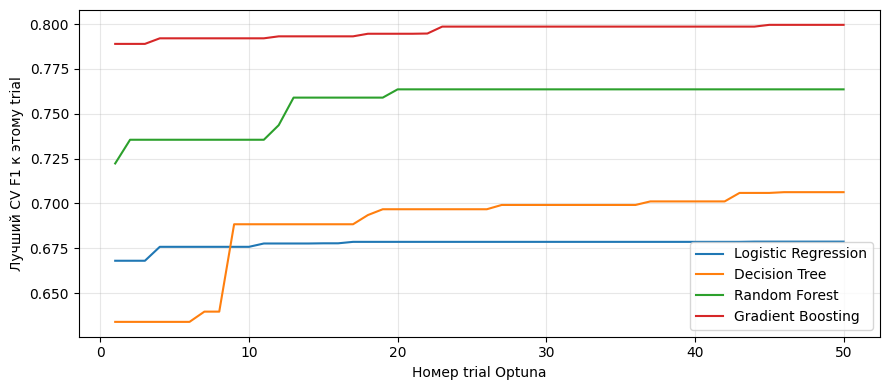

In [14]:
fig, ax = plt.subplots(figsize=(9, 4))
for name in names:
    values = np.array([t.value for t in studies[name].trials])
    best = np.maximum.accumulate(values)
    ax.plot(range(1, 51), best, label=name)
    print(f"{name}: максимум на trial {values.argmax() + 1}, прирост после trial 40 = {best[-1] - best[39]:.4f}")
ax.set_xlabel("Номер trial Optuna")
ax.set_ylabel("Лучший CV F1 к этому trial")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Глубина дерева

EXP-002. Меняю только `max_depth` и смотрю, где расходятся train и CV.

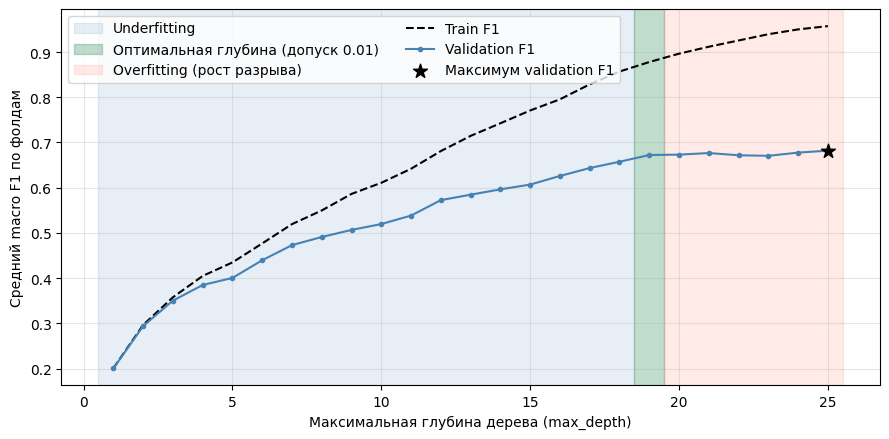

Глубина  1: train F1 = 0.201, validation F1 = 0.201
Глубина 19: train F1 = 0.878, validation F1 = 0.672
Глубина 25: train F1 = 0.957, validation F1 = 0.682


In [15]:
depths = np.arange(1, 26)
train_f1, val_f1 = [], []
for depth in depths:
    model = make_model(TREE, {"max_depth": int(depth)})
    scores = cross_validate(model, X_dev, y_dev, cv=cv, scoring="f1_macro", return_train_score=True)
    train_f1.append(scores["train_score"].mean())
    val_f1.append(scores["test_score"].mean())

depth_best = depths[np.argmax(val_f1)]
# Самое простое дерево, которое уступает максимуму не более 0.01 macro F1
depth_simple = depths[np.flatnonzero(np.array(val_f1) >= max(val_f1) - 0.01)[0]]
plt.figure(figsize=(9, 4.5))
plt.axvspan(0.5, depth_simple - 0.5, alpha=0.13, color="steelblue", label="Underfitting")
plt.axvspan(depth_simple - 0.5, depth_simple + 0.5, alpha=0.3, color="seagreen", label="Оптимальная глубина (допуск 0.01)")
plt.axvspan(depth_simple + 0.5, 25.5, alpha=0.13, color="tomato", label="Overfitting (рост разрыва)")
plt.plot(depths, train_f1, "--", color="black", label="Train F1")
plt.plot(depths, val_f1, "o-", color="steelblue", ms=3, label="Validation F1")
plt.scatter(depth_best, max(val_f1), marker="*", s=110, color="black", zorder=3, label="Максимум validation F1")
plt.xlabel("Максимальная глубина дерева (max_depth)")
plt.ylabel("Средний macro F1 по фолдам")
plt.grid(alpha=0.3)
plt.legend(ncol=2)
plt.tight_layout()
plt.show()
for i in sorted({0, int(depth_simple) - 1, int(depth_best) - 1, len(depths) - 1}):
    print(f"Глубина {depths[i]:2}: train F1 = {train_f1[i]:.3f}, validation F1 = {val_f1[i]:.3f}")

## Число деревьев в ансамблях

EXP-003. Меняю только `n_estimators` и сравниваю macro F1 и время обучения.

In [16]:
rows = []
sizes = [1, 10, 50, 100, 200, 400]
for name in [FOREST, BOOSTING]:
    for size in sizes:
        params = {**best_params[name], "n_estimators": size}
        cv_f1 = cv_scores(make_model(name, params)).mean()
        model, fit_s = fit_timed(name, params)
        rows.append({"Модель": name, "n_estimators": size, "CV F1": cv_f1,
                     "Обучение, с": fit_s, "1 объект, мс": latency_ms(model, X_dev)})

ensemble = pd.DataFrame(rows)
ensemble.round(4)

,Модель,n_estimators,CV F1,"Обучение, с","1 объект, мс"
0,Random Forest,1,0.6512,0.0742,6.3919
1,Random Forest,10,0.7413,0.6448,7.2913
2,Random Forest,50,0.7597,2.9489,9.0097
3,Random Forest,100,0.7644,5.8997,16.2631
4,Random Forest,200,0.7633,11.6087,17.1951
5,Random Forest,400,0.7632,23.1130,27.4857
6,Gradient Boosting,1,0.1094,0.0489,7.5782
7,Gradient Boosting,10,0.6691,0.0931,6.9184
8,Gradient Boosting,50,0.7768,0.2152,7.0879
9,Gradient Boosting,100,0.7954,0.4543,7.5516


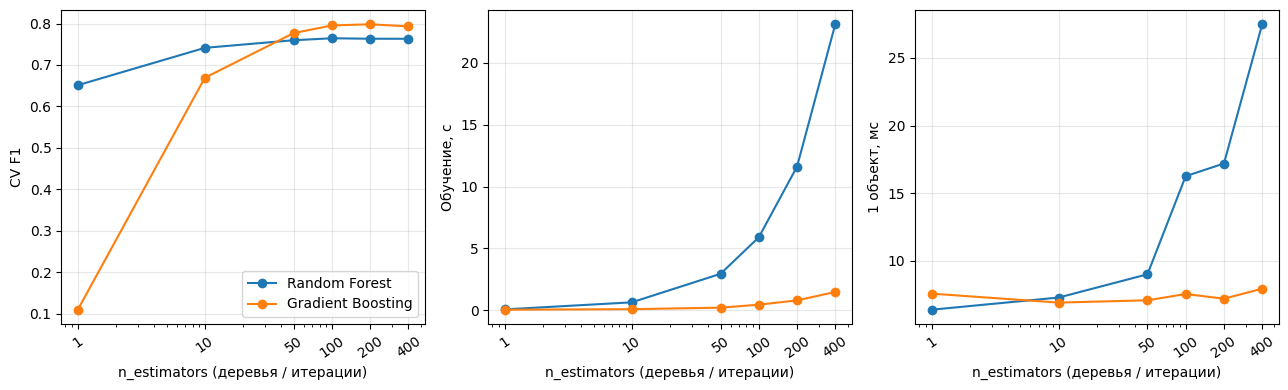

Начало плато леса: 50


In [17]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col in zip(axes, ["CV F1", "Обучение, с", "1 объект, мс"]):
    for name, group in ensemble.groupby("Модель", sort=False):
        ax.plot(group["n_estimators"], group[col], "o-", label=name)
    ax.set_xscale("log")
    ax.set_xticks(sizes, labels=sizes, rotation=35)
    ax.set_xlabel("n_estimators (деревья / итерации)")
    ax.set_ylabel(col)
    ax.grid(alpha=0.3)
axes[0].legend()
plt.tight_layout()
plt.show()

# Первая точка, после которой прибавка к качеству нигде не достигает 0.005
forest_curve = ensemble[ensemble["Модель"] == FOREST].set_index("n_estimators")["CV F1"]
plateau = next((k for k in sizes[:-1] if forest_curve.loc[k:].max() - forest_curve[k] < 0.005), None)
print("Начало плато леса:", plateau if plateau else "на этой сетке плато не видно")

## Macro F1 и micro F1

Для ориентира добавляю константу, которая всегда предсказывает ESI-3.

In [18]:
def metrics(pred):
    per_class = f1_score(y_hold, pred, labels=classes, average=None, zero_division=0)
    return {"macro F1": f1_score(y_hold, pred, average="macro"),
            "micro F1": f1_score(y_hold, pred, average="micro"),
            **{f"ESI-{k}": score for k, score in zip(classes, per_class)},
            "MAE, уровни": mean_absolute_error(y_hold, pred)}

metric_columns = ["macro F1", "micro F1", *[f"ESI-{k}" for k in classes]]
constant = np.full(len(y_hold), y_dev.mode().iloc[0])
by_class = pd.DataFrame({name: metrics(pred) for name, pred in
                         {"Константа": constant, **predictions}.items()}).T
print(f"{winner}: accuracy = {accuracy_score(y_hold, predictions[winner]):.4f},",
      f"micro F1 = {by_class.loc[winner, 'micro F1']:.4f}")
by_class[metric_columns].rename_axis("Модель").round(4).reset_index()

Gradient Boosting: accuracy = 0.8125, micro F1 = 0.8125


,Модель,macro F1,micro F1,ESI-1,ESI-2,ESI-3,ESI-4,ESI-5
0,Константа,0.1094,0.3762,0.0000,0.0000,0.5468,0.0000,0.0000
1,Logistic Regression,0.6834,0.7088,0.8172,0.3930,0.7754,0.6916,0.7396
2,Decision Tree,0.7056,0.7456,0.7674,0.4526,0.8111,0.7621,0.7347
3,Random Forest,0.7669,0.7969,0.8431,0.5240,0.8574,0.7888,0.8213
4,Gradient Boosting,0.7930,0.8125,0.8750,0.5836,0.8590,0.8140,0.8337


### Когда метрики по-разному ранжируют модели

In [19]:
stump = make_model(TREE, {"max_depth": 1, "class_weight": "balanced"}).fit(X_dev, y_dev)
stump_pred = stump.predict(X_hold)
print("Классы в прогнозах Decision Tree:", [f"ESI-{k}" for k in np.unique(stump_pred)])
ranking_pair = pd.DataFrame({
    "Константа": metrics(constant),
    "Decision Tree (глубина 1, balanced)": metrics(stump_pred),
}).T
ranking_pair[metric_columns].rename_axis("Модель").round(4).reset_index()

Классы в прогнозах Decision Tree: ['ESI-1', 'ESI-4']


,Модель,macro F1,micro F1,ESI-1,ESI-2,ESI-3,ESI-4,ESI-5
0,Константа,0.1094,0.3762,0.0000,0.0,0.5468,0.0000,0.0
1,"Decision Tree (глубина 1, balanced)",0.2172,0.3419,0.5854,0.0,0.0000,0.5005,0.0


In [20]:
# В EXP-003 уже есть короткий бустинг. Сравним его с логистической регрессией.
short_params = {**best_params[BOOSTING], "n_estimators": 10}
pair = {LOGISTIC: make_model(LOGISTIC, best_params[LOGISTIC]),
        f"{BOOSTING}, 10 итераций": make_model(BOOSTING, short_params)}
rows = []
for name, model in pair.items():
    fold_rows = []
    for tr, va in cv.split(X_dev, y_dev):
        model.fit(X_dev.iloc[tr], y_dev.iloc[tr])
        pred = model.predict(X_dev.iloc[va])
        true = y_dev.iloc[va]
        per = f1_score(true, pred, labels=classes, average=None, zero_division=0)
        fold_rows.append({"macro F1": per.mean(), "micro F1": accuracy_score(true, pred),
                          **{f"ESI-{k}": f for k, f in zip(classes, per)}})
    rows.append({"Выборка": "CV", "Модель": name, **pd.DataFrame(fold_rows).mean().to_dict()})
    model.fit(X_dev, y_dev)
    row = metrics(model.predict(X_hold))
    rows.append({"Выборка": "holdout", "Модель": name,
                 **{col: row[col] for col in fold_rows[0]}})
pd.DataFrame(rows).set_index(["Выборка", "Модель"]).sort_index().round(4)

macro F1  micro F1   ESI-1   ESI-2   ESI-3   ESI-4   ESI-5
Выборка Модель                                                                                    
CV      Gradient Boosting, 10 итераций    0.6691    0.7058  0.7349  0.4422  0.7503  0.7190  0.6991
        Logistic Regression               0.6788    0.6998  0.8067  0.4076  0.7460  0.7057  0.7278
holdout Gradient Boosting, 10 итераций    0.6780    0.7025  0.8182  0.3941  0.7535  0.6975  0.7268
        Logistic Regression               0.6834    0.7088  0.8172  0.3930  0.7754  0.6916  0.7396

### Подбор дерева по micro F1 и macro F1

Меняю метрику Optuna. Пространство поиска, бюджет, фолды и seed совпадают.

In [21]:
micro_study = tune(TREE, "f1_micro")
print("Decision Tree под micro F1:", micro_study.best_params)
print(f"CV micro F1 = {micro_study.best_value:.4f}")

Decision Tree под micro F1: {'class_weight': None, 'max_depth': 21, 'min_samples_leaf': 11, 'criterion': 'gini'}
CV micro F1 = 0.7500


In [22]:
tree_micro = make_model(TREE, micro_study.best_params).fit(X_dev, y_dev)
tree_metrics = pd.DataFrame([
    {
        "Метрика Optuna": "micro F1",
        "Лучшие гиперпараметры": micro_study.best_params,
        **metrics(tree_micro.predict(X_hold)),
    },
    {
        "Метрика Optuna": "macro F1",
        "Лучшие гиперпараметры": best_params[TREE],
        **metrics(predictions[TREE]),
    },
])
with pd.option_context("display.max_colwidth", None):
    display(tree_metrics[["Метрика Optuna", "Лучшие гиперпараметры", *metric_columns]].round(4))

,Метрика Optuna,Лучшие гиперпараметры,macro F1,micro F1,ESI-1,ESI-2,ESI-3,ESI-4,ESI-5
0,micro F1,"{'class_weight': None, 'max_depth': 21, 'min_samples_leaf': 11, 'criterion': 'gini'}",0.7084,0.7481,0.7674,0.4615,0.8140,0.7619,0.7371
1,macro F1,"{'class_weight': None, 'max_depth': 21, 'min_samples_leaf': 10, 'criterion': 'gini'}",0.7056,0.7456,0.7674,0.4526,0.8111,0.7621,0.7347


### Матрица ошибок бустинга

In [23]:
cm = confusion_matrix(y_hold, predictions[winner], labels=classes)
labels = [f"ESI-{k}" for k in classes]
pd.DataFrame(cm, index=labels, columns=labels).rename_axis(index="Истинный класс", columns="Прогноз")

Прогноз,ESI-1,ESI-2,ESI-3,ESI-4,ESI-5
Истинный класс,,,,,
ESI-1,42,6,0,1,0
ESI-2,5,96,59,34,15
ESI-3,0,16,533,52,1
ESI-4,0,2,46,431,44
ESI-5,0,0,1,18,198


## SHAP и важность признаков

### Важность по классам

Складываю вклады one-hot-столбцов внутри исходного признака, затем усредняю модуль вклада по объектам.

In [24]:
gb_pipe = models[BOOSTING]
prep, gb = gb_pipe.steps[0][1], gb_pipe.steps[1][1]
encoded = prep.transform(X_hold)
feat_names = list(encoded.columns)
class_order = list(gb.classes_)
raw = np.asarray(gb.predict(encoded, pred_contrib=True))
parts = raw.reshape(len(encoded), len(class_order), len(feat_names) + 1)
assert np.allclose(parts.sum(axis=2), gb.predict(encoded, raw_score=True))

# Индексы столбцов каждого исходного признака после one-hot
groups = {c: [i for i, name in enumerate(feat_names)
              if name == c or (c in cat_cols and name.startswith(c + "_"))] for c in X_dev}
assert sorted(i for group in groups.values() for i in group) == list(range(len(feat_names)))
sv = np.stack([parts[:, :, idx].sum(axis=2) for idx in groups.values()], axis=2)
importance = pd.DataFrame(np.abs(sv).mean(axis=0).T, index=X_dev.columns, columns=class_order)
importance.index.name = "Признак"
importance.sort_values(1, ascending=False).rename(columns=lambda k: f"ESI-{k}").round(3)

,ESI-1,ESI-2,ESI-3,ESI-4,ESI-5
Признак,,,,,
chief_complaint,0.291,0.264,0.902,0.900,1.058
pain_score,0.281,0.052,0.118,0.211,0.271
weight_kg,0.273,0.055,0.016,0.014,0.023
heart_rate,0.256,0.143,0.017,0.006,0.026
gcs,0.243,0.087,0.054,0.038,0.000
sbp,0.169,0.095,0.016,0.011,0.055
resp_rate,0.161,0.041,0.029,0.008,0.008
dbp,0.148,0.028,0.004,0.015,0.012
spo2,0.144,0.081,0.056,0.060,0.024


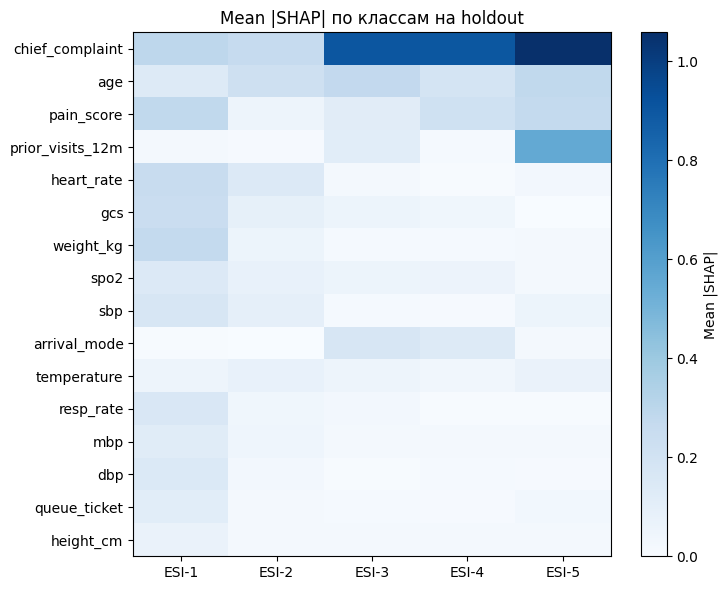

In [25]:
fig, ax = plt.subplots(figsize=(7.5, 6))
order = importance.mean(axis=1).sort_values(ascending=False).index
im = ax.imshow(importance.loc[order], cmap="Blues", aspect="auto")
ax.set_yticks(range(len(order)), order)
ax.set_xticks(range(len(class_order)), [f"ESI-{k}" for k in class_order])
ax.set_title("Mean |SHAP| по классам на holdout")
fig.colorbar(im, ax=ax, label="Mean |SHAP|")
plt.tight_layout()
plt.show()

### Dependence plot

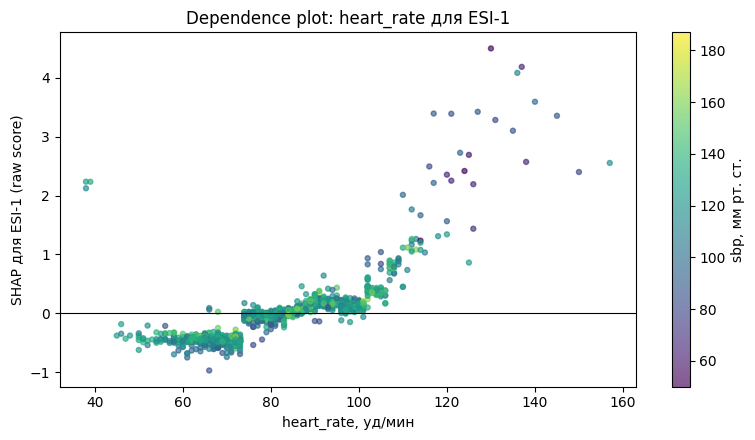

sbp            (0.0, 100.0]  (100.0, 140.0]  (140.0, inf]
heart_rate                                               
(0.0, 60.0]           -0.57           -0.45         -0.34
(60.0, 90.0]          -0.16           -0.03         -0.04
(90.0, 110.0]          0.25            0.17          0.19
(110.0, inf]           2.57            1.22          1.10


In [26]:
pulse_shap = sv[:, class_order.index(1), list(groups).index("heart_rate")]
plt.figure(figsize=(8, 4.5))
dots = plt.scatter(X_hold.heart_rate, pulse_shap, c=X_hold.sbp, cmap="viridis",
                   s=13, alpha=0.65)
plt.colorbar(dots, label="sbp, мм рт. ст.")
plt.axhline(0, color="black", lw=0.8)
plt.xlabel("heart_rate, уд/мин")
plt.ylabel("SHAP для ESI-1 (raw score)")
plt.title("Dependence plot: heart_rate для ESI-1")
plt.tight_layout()
plt.show()

# Медианный вклад по диапазонам пульса и давления помогает прочитать облако точек
print(pd.crosstab(pd.cut(X_hold.heart_rate, [0, 60, 90, 110, np.inf]),
                  pd.cut(X_hold.sbp, [0, 100, 140, np.inf]),
                  values=pulse_shap, aggfunc="median").round(2))

На графике можно сравнить вклад одинакового пульса в оценку ESI-1 при разном давлении.

### MDI, permutation importance и SHAP

MDI и перестановки считаю для леса, SHAP — для бустинга.

In [27]:
rf_pipe = models[FOREST]
assert list(rf_pipe[0].get_feature_names_out()) == feat_names
mdi = rf_pipe[-1].feature_importances_
perm = permutation_importance(rf_pipe, X_hold, y_hold, scoring="f1_macro",
                              n_repeats=10, random_state=RANDOM_STATE)
importance_all = pd.DataFrame({
    "MDI": [mdi[idx].sum() for idx in groups.values()],
    "Perm.": perm.importances_mean,
    "SHAP": importance.mean(axis=1),
}, index=X_dev.columns)
ranks = importance_all.rank(ascending=False, method="min").astype(int)
ranks.sort_values("Perm.").rename_axis("Признак").reset_index()

,Признак,MDI,Perm.,SHAP
0,chief_complaint,1,1,1
1,age,4,2,2
2,prior_visits_12m,6,3,4
3,gcs,2,4,6
4,spo2,5,5,8
5,heart_rate,3,6,5
6,sbp,7,7,9
7,arrival_mode,15,8,10
8,pain_score,9,9,3
9,temperature,8,10,11


Показатели давления сильно связаны. При перестановке одного лес всё ещё видит остальные.

## Эксперименты и сабмиты

### Базовые модели

Переобучаю четыре модели на всём `train`. Лучший базовый вариант сохраняю в `submission.csv`.

In [28]:
sample = pd.read_csv(data / "sample_submission.csv")
X_test = test[X.columns]
assert test.id.is_unique and sample.id.is_unique and set(test.id) == set(sample.id)
folder = data / "submissions"
folder.mkdir(exist_ok=True)
file_names = {LOGISTIC: "logreg", TREE: "tree", FOREST: "forest", BOOSTING: "lightgbm"}

for name in names:
    final = make_model(name, best_params[name]).fit(X, y)
    pred = pd.Series(final.predict(X_test), index=test.id)
    submission = pd.DataFrame({"id": sample.id, "esi": sample.id.map(pred)})
    assert submission.columns.tolist() == sample.columns.tolist()
    assert len(submission) == len(test) and submission.esi.isin(classes).all()
    assert pd.api.types.is_integer_dtype(submission.esi)
    submission.to_csv(folder / f"{file_names[name]}.csv", index=False)
    if name == winner:
        submission.to_csv(work / "submission.csv", index=False)

submission = pd.read_csv(work / "submission.csv")
print("Лучшая базовая модель по CV F1:", winner)
print("Строк в submission.csv:", len(submission))
submission.head()

Лучшая базовая модель по CV F1: Gradient Boosting
Строк в submission.csv: 5000


,id,esi
0,100000,2
1,100001,3
2,100002,5
3,100003,4
4,100004,3


### Варианты LightGBM

Сравниваю обычный бустинг, встроенную обработку категорий и поэтапный прогноз ESI. Коэффициент для ESI-2 подбираю на внутренних фолдах.

In [29]:
from sklearn.preprocessing import OrdinalEncoder

variants = ["Исходный", "Категории", "По этапам"]
gb_params = best_params[BOOSTING]
esi2_weights = np.array([1.0, 0.9, 1.1, 1.2, 1.35, 1.5, 1.75])

def fit_variant(kind, X_fit, y_fit):
    if kind == "Исходный":
        return make_model(BOOSTING, gb_params).fit(X_fit, y_fit)

    encoder = ColumnTransformer([
        ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
        ("num", "passthrough", num_cols),
    ], verbose_feature_names_out=False).set_output(transform="pandas")
    frame = encoder.fit_transform(X_fit)

    def fit_gbm(rows, target):
        model = lgb.LGBMClassifier(**gb_params, random_state=RANDOM_STATE, n_jobs=1, verbosity=-1)
        return model.fit(frame.loc[rows], target, categorical_feature=cat_cols)

    if kind == "Категории":
        return make_pipeline(encoder, fit_gbm(y_fit.index, y_fit))

    later = y_fit > 1
    stable = y_fit > 2
    first = fit_gbm(y_fit.index, y_fit.eq(1))
    second = fit_gbm(later, y_fit.loc[later].eq(2))
    last = fit_gbm(stable, y_fit.loc[stable])
    return encoder, first, second, last


def variant_proba(kind, model, frame):
    if kind != "По этапам":
        return model.predict_proba(frame)
    encoder, first, second, last = model
    encoded = encoder.transform(frame)
    p1 = first.predict_proba(encoded)[:, 1]
    p2 = (1 - p1) * second.predict_proba(encoded)[:, 1]
    rest = (1 - p1 - p2)[:, None] * last.predict_proba(encoded)
    return np.column_stack([p1, p2, rest])


def choose_esi(proba, weight):
    adjusted = proba.copy()
    adjusted[:, 1] *= weight
    return classes[adjusted.argmax(axis=1)]


def best_weight(proba, true):
    scores = [f1_score(true, choose_esi(proba, w), average="macro") for w in esi2_weights]
    return min(zip(scores, esi2_weights), key=lambda pair: (-pair[0], abs(pair[1] - 1)))[1]

In [30]:
oof = {kind: np.zeros((len(y_dev), len(classes))) for kind in variants}
rows = []
for fold, (tr, va) in enumerate(cv.split(X_dev, y_dev), 1):
    fold_X, fold_y = X_dev.iloc[tr], y_dev.iloc[tr]
    inner = StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE)
    for kind in variants:
        inner_prob = np.zeros((len(tr), len(classes)))
        for a, b in inner.split(fold_X, fold_y):
            model = fit_variant(kind, fold_X.iloc[a], fold_y.iloc[a])
            inner_prob[b] = variant_proba(kind, model, fold_X.iloc[b])
        weight = best_weight(inner_prob, fold_y)

        model = fit_variant(kind, fold_X, fold_y)
        prob = variant_proba(kind, model, X_dev.iloc[va])
        assert np.allclose(prob.sum(axis=1), 1) and np.all(prob >= 0)
        oof[kind][va] = prob
        for rule, w in [("Без поправки", 1.0), ("Вес ESI-2", weight)]:
            pred = choose_esi(prob, w)
            per = f1_score(y_dev.iloc[va], pred, average=None, labels=classes)
            rows.append({"Фолд": fold, "Модель": kind, "правило": rule, "вес": w,
                         "macro F1": per.mean(), **{f"ESI-{k}": f for k, f in zip(classes, per)}})

folds = pd.DataFrame(rows)
summary = folds.groupby(["Модель", "правило"], sort=False)[["macro F1", *[f"ESI-{k}" for k in classes]]].mean()
summary = summary.sort_values("macro F1", ascending=False, kind="stable")
best_kind, best_rule = summary.index[0]
summary.round(5)

macro F1    ESI-1    ESI-2    ESI-3    ESI-4    ESI-5
Модель    правило                                                            
По этапам Вес ESI-2      0.80162  0.81454  0.64400  0.86907  0.83174  0.84873
Исходный  Вес ESI-2      0.80144  0.85637  0.64056  0.86126  0.81712  0.83192
По этапам Без поправки   0.80033  0.81353  0.63699  0.86980  0.83102  0.85031
Исходный  Без поправки   0.79954  0.85402  0.63223  0.86215  0.81789  0.83141
Категории Вес ESI-2      0.79545  0.80317  0.63435  0.86843  0.82823  0.84309
          Без поправки   0.79446  0.80399  0.62799  0.86811  0.82816  0.84408

In [31]:
base_rows = folds[(folds["Модель"] == "Исходный") & (folds["правило"] == "Без поправки")].set_index("Фолд")
chosen = folds[(folds["Модель"] == best_kind) & (folds["правило"] == best_rule)].set_index("Фолд")
paired = pd.DataFrame({"SUB-001": base_rows["macro F1"], "кандидат": chosen["macro F1"],
                       "разница": chosen["macro F1"] - base_rows["macro F1"], "вес ESI-2": chosen["вес"]})
final_weight = best_weight(oof[best_kind], y_dev) if best_rule == "Вес ESI-2" else 1.0
print("Выбор по CV:", best_kind, "|", best_rule, "| вес по прогнозам вне фолда:", final_weight)
paired.round(5)

Выбор по CV: По этапам | Вес ESI-2 | вес по прогнозам вне фолда: 1.5


,SUB-001,кандидат,разница,вес ESI-2
Фолд,,,,
1,0.79363,0.79518,0.00155,1.50
2,0.81684,0.81406,-0.00278,1.20
3,0.78776,0.78574,-0.00201,1.50
4,0.79697,0.81088,0.01391,1.75
5,0.80250,0.80221,-0.00029,1.75


In [32]:
candidate = fit_variant(best_kind, X_dev, y_dev)
hold_prob = variant_proba(best_kind, candidate, X_hold)
hold_pred = choose_esi(hold_prob, final_weight)
print("Ответ изменился у", (hold_pred != predictions[BOOSTING]).sum(), "из", len(y_hold), "пациентов")
pd.DataFrame({"SUB-001": metrics(predictions[BOOSTING]), "Кандидат": metrics(hold_pred)}).T.round(5)

Ответ изменился у 79 из 1600 пациентов


,macro F1,micro F1,ESI-1,ESI-2,ESI-3,ESI-4,ESI-5,"MAE, уровни"
SUB-001,0.79305,0.81250,0.87500,0.58359,0.85898,0.81398,0.83368,0.23125
Кандидат,0.79081,0.81875,0.84783,0.56548,0.86730,0.82613,0.84731,0.22562


### Усреднение вероятностей (SUB-005)

Смешиваю два LightGBM поровну. Проверяю выигрыш на трёх разбиениях и смотрю, помогает ли поправка для ESI-2.

In [33]:
def base_and_blend(X_fit, y_fit, X_check):
    base = fit_variant("Исходный", X_fit, y_fit)
    staged = fit_variant("По этапам", X_fit, y_fit)
    base_prob = variant_proba("Исходный", base, X_check)
    staged_prob = variant_proba("По этапам", staged, X_check)
    blended = (base_prob + staged_prob) / 2
    assert np.isfinite(blended).all() and np.allclose(blended.sum(axis=1), 1)
    return base_prob, blended


seeds = [42, 113, 271]
blend_oof = []
blend_rows = []
for seed in seeds:
    splits = StratifiedKFold(5, shuffle=True, random_state=seed)
    repeat_prob = np.zeros((len(y_dev), len(classes)))
    for fold, (tr, va) in enumerate(splits.split(X_dev, y_dev), 1):
        train_x, train_y = X_dev.iloc[tr], y_dev.iloc[tr]
        inner = StratifiedKFold(3, shuffle=True, random_state=seed)
        inner_prob = np.zeros((len(tr), len(classes)))
        for a, b in inner.split(train_x, train_y):
            _, inner_prob[b] = base_and_blend(train_x.iloc[a], train_y.iloc[a], train_x.iloc[b])
        weight = best_weight(inner_prob, train_y)

        base_prob, repeat_prob[va] = base_and_blend(train_x, train_y, X_dev.iloc[va])
        true = y_dev.iloc[va]
        base_f1 = f1_score(true, choose_esi(base_prob, 1), average="macro")
        plain_f1 = f1_score(true, choose_esi(repeat_prob[va], 1), average="macro")
        blend_f1 = f1_score(true, choose_esi(repeat_prob[va], weight), average="macro")
        blend_rows.append({"seed": seed, "Фолд": fold, "вес ESI-2": weight, "SUB-001": base_f1,
                           "смесь": plain_f1, "смесь с поправкой": blend_f1, "разница": blend_f1 - base_f1})
    blend_oof.append(repeat_prob)

blend_folds = pd.DataFrame(blend_rows)
rules = ["смесь", "смесь с поправкой"]
by_seed = blend_folds.groupby("seed")[["SUB-001", *rules]].mean()
wins = {rule: int((blend_folds[rule] > blend_folds["SUB-001"]).sum()) for rule in rules}
eligible = [rule for rule in rules if wins[rule] >= 9 and (by_seed[rule] > by_seed["SUB-001"]).all()]
chosen_rule = max(eligible, key=lambda rule: by_seed[rule].mean()) if eligible else "SUB-001"
print("Выигрыши из 15 парных сравнений:", wins)
print("Выбор по CV:", chosen_rule)
by_seed.round(5)

Выигрыши из 15 парных сравнений: {'смесь': 10, 'смесь с поправкой': 10}
Выбор по CV: смесь


,SUB-001,смесь,смесь с поправкой
seed,,,
42,0.79954,0.80468,0.80442
113,0.79518,0.79909,0.79856
271,0.79353,0.79780,0.79779


In [34]:
tuned_weight = best_weight(np.concatenate(blend_oof), np.tile(y_dev.to_numpy(), len(seeds)))
blend_weight = tuned_weight if chosen_rule == "смесь с поправкой" else 1.0
print("По прогнозам вне фолда вес для варианта с поправкой:", tuned_weight)
print("Вес в выбранной модели:", blend_weight)
print("Средний macro F1 по трём разбиениям:")
print(by_seed.mean().round(5))
blend_folds["разница"] = blend_folds[chosen_rule] - blend_folds["SUB-001"]
blend_folds.pivot(index="Фолд", columns="seed", values="разница").round(5)

По прогнозам вне фолда вес для варианта с поправкой: 1.2
Вес в выбранной модели: 1.0
Средний macro F1 по трём разбиениям:
SUB-001              0.79609
смесь                0.80052
смесь с поправкой    0.80025
dtype: float64


seed,42,113,271
Фолд,,,
1,0.00731,-0.01062,-0.00647
2,0.00739,0.01813,0.00953
3,-0.00710,-0.00289,0.00127
4,0.01398,-0.00005,0.00965
5,0.00411,0.01497,0.00734


Смесь выбираю по CV. На holdout смотрю, в каких классах меняются ошибки.

In [35]:
# В замер включаем обе обработки признаков и все четыре бустинга.
start = time.perf_counter()
base_model = fit_variant("Исходный", X_dev, y_dev)
stage_model = fit_variant("По этапам", X_dev, y_dev)
blend_fit_s = time.perf_counter() - start

def predict_pair(frame):
    p_base = variant_proba("Исходный", base_model, frame)
    p_stage = variant_proba("По этапам", stage_model, frame)
    return choose_esi((p_base + p_stage) / 2, blend_weight)

row = X_hold.iloc[[0]]
predict_pair(row)
times = []
for _ in range(100):
    start = time.perf_counter()
    predict_pair(row)
    times.append(time.perf_counter() - start)
blend_latency_ms = 1000 * np.median(times)
print(f"Обучение, с: {blend_fit_s:.4f}. 1 объект, мс: {blend_latency_ms:.4f}.")
blend_hold_pred = predict_pair(X_hold)
pd.DataFrame({"SUB-001": metrics(predictions[BOOSTING]),
              "Смесь": metrics(blend_hold_pred)}).T.round(5)

Обучение, с: 1.5919. 1 объект, мс: 17.8733.


,macro F1,micro F1,ESI-1,ESI-2,ESI-3,ESI-4,ESI-5,"MAE, уровни"
SUB-001,0.79305,0.8125,0.87500,0.58359,0.85898,0.81398,0.83368,0.23125
Смесь,0.79643,0.8200,0.87234,0.57407,0.86819,0.82139,0.84615,0.22438


In [36]:
if chosen_rule != "SUB-001":
    _, test_prob = base_and_blend(X, y, X_test)
    pred = pd.Series(choose_esi(test_prob, blend_weight), index=test.id)
    candidate_submission = sample[["id"]].assign(esi=sample.id.map(pred))
    assert candidate_submission.id.is_unique and candidate_submission.id.equals(sample.id)
    assert len(candidate_submission) == len(test) and candidate_submission.esi.isin(classes).all()
    assert pd.api.types.is_integer_dtype(candidate_submission.esi)
    candidate_path = folder / "lightgbm_mix.csv"
    candidate_submission.to_csv(candidate_path, index=False)
    original = pd.read_csv(folder / "lightgbm.csv")
    assert candidate_submission.id.equals(original.id)
    print(candidate_path.name, "— строк:", len(candidate_submission),
          "  изменились ответы:", (candidate_submission.esi != original.esi).sum())
else:
    print("По правилу отбора оставляем SUB-001.")

lightgbm_mix.csv — строк: 5000   изменились ответы: 134


### Дополнительные признаки и CatBoost (SUB-006)

Добавляю производные числовые признаки и проверяю смеси с CatBoost. Частоты классов по жалобе для обучающих строк считаю на внутренних фолдах.

In [37]:
from catboost import CatBoostClassifier
from sklearn.preprocessing import TargetEncoder

def extra_features(frame):
    return frame.assign(
        pulse_to_sbp=frame.heart_rate / frame.sbp,
        pulse_pressure=frame.sbp - frame.dbp,
        spo2_to_resp=frame.spo2 / frame.resp_rate,
        bmi=frame.weight_kg / (frame.height_cm / 100) ** 2,
    )


def make_extra(name):
    if name == "CatBoost":
        return CatBoostClassifier(iterations=600, depth=5, learning_rate=0.065,
                                  l2_leaf_reg=4, one_hot_max_size=4, max_ctr_complexity=1,
                                  cat_features=cat_cols, random_seed=RANDOM_STATE,
                                  thread_count=4, verbose=False, allow_writing_files=False)
    prep = ColumnTransformer([
        ("частоты", TargetEncoder(target_type="multiclass", smooth=10, cv=5,
                                  shuffle=True, random_state=RANDOM_STATE), ["chief_complaint"]),
        ("категории", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ], remainder="passthrough").set_output(transform="pandas")
    gb = lgb.LGBMClassifier(**gb_params, random_state=RANDOM_STATE, n_jobs=1, verbosity=-1)
    return make_pipeline(prep, gb)


# Названия компонентов в каждой смеси. Вероятности усредняем с одинаковыми весами.
recipes = {
    "SUB-005": ("SUB-005",),
    "Частоты": ("Частоты",),
    "CatBoost": ("CatBoost",),
    "SUB-005 + частоты": ("SUB-005", "Частоты"),
    "SUB-005 + CatBoost": ("SUB-005", "CatBoost"),
    "Три модели": ("SUB-005", "Частоты", "CatBoost"),
}


def component_probs(train_x, train_y, check_x, needed):
    probs = {}
    if "SUB-005" in needed:
        _, probs["SUB-005"] = base_and_blend(train_x, train_y, check_x)
    for name in needed:
        if name != "SUB-005":
            model = make_extra(name).fit(extra_features(train_x), train_y)
            assert np.array_equal(model.classes_, classes)
            probs[name] = model.predict_proba(extra_features(check_x))
    return probs


def recipe_pred(probs, parts):
    avg = np.mean([probs[name] for name in parts], axis=0)
    assert np.isfinite(avg).all() and np.allclose(avg.sum(axis=1), 1)
    return classes[avg.argmax(axis=1)]

In [38]:
def compare_recipes(seed, names):
    rows = []
    needed = list(dict.fromkeys(part for name in names for part in recipes[name]))
    split = StratifiedKFold(5, shuffle=True, random_state=seed)
    for fold, (tr, va) in enumerate(split.split(X_dev, y_dev), 1):
        probs = component_probs(X_dev.iloc[tr], y_dev.iloc[tr], X_dev.iloc[va], needed)
        rows.append({"seed": seed, "Фолд": fold,
                     **{name: f1_score(y_dev.iloc[va], recipe_pred(probs, recipes[name]), average="macro")
                        for name in names}})
    return pd.DataFrame(rows).set_index(["seed", "Фолд"])

experiments = pd.concat([compare_recipes(seed, recipes) for seed in seeds])
means = experiments.groupby(level="seed").mean()
gains = means.sub(means["SUB-005"], axis=0)
win_count = experiments.gt(experiments["SUB-005"], axis=0).sum()
eligible_recipes = [name for name in recipes if (gains[name] > 0).all() and win_count[name] >= 9]
winner_next = max(eligible_recipes, key=lambda name: means[name].mean()) if eligible_recipes else "SUB-005"

comparison = means.T.assign(среднее=means.mean(), прирост=gains.mean(), выигрышей=win_count)
print("Выбор по CV:", winner_next)
comparison.sort_values("среднее", ascending=False).round(5)

Выбор по CV: Три модели


seed,42,113,271,среднее,прирост,выигрышей
Три модели,0.81373,0.80859,0.80867,0.81033,0.00981,14
SUB-005 + частоты,0.81374,0.80837,0.80726,0.80979,0.00926,14
Частоты,0.81262,0.80731,0.80713,0.80902,0.00850,14
SUB-005 + CatBoost,0.80793,0.80187,0.80169,0.80383,0.00331,10
SUB-005,0.80468,0.79909,0.79780,0.80052,0.00000,0
CatBoost,0.78960,0.79119,0.78447,0.78842,-0.01210,2


In [39]:
if winner_next != "SUB-005":
    check = compare_recipes(2026, ["SUB-005", winner_next])
    check["разница"] = check[winner_next] - check["SUB-005"]
    confirmed = check["разница"].mean() > 0
    print(check.round(5))
    print("Средние на новом разбиении:")
    print(check.mean().round(5))
else:
    confirmed = False
print("Есть кандидат по правилу отбора:", confirmed)

           SUB-005  Три модели  разница
seed Фолд                              
2026 1     0.79117     0.78657 -0.00460
     2     0.80408     0.81189  0.00781
     3     0.79770     0.80765  0.00995
     4     0.80942     0.81939  0.00997
     5     0.80787     0.82701  0.01913
Средние на новом разбиении:
SUB-005       0.80205
Три модели    0.81050
разница       0.00845
dtype: float64
Есть кандидат по правилу отбора: True


In [40]:
if confirmed:
    parts = recipes[winner_next]
    hold_probs = component_probs(X_dev, y_dev, X_hold, list(dict.fromkeys(("SUB-005", *parts))))
    hold_compare = pd.DataFrame({
        name: metrics(recipe_pred(hold_probs, recipes[name])) for name in ["SUB-005", winner_next]
    }).T
    print("Ошибки уже выбранной модели на знакомом holdout:")
    print(hold_compare.round(5))

    test_probs = component_probs(X, y, X_test, parts)
    test_pred = pd.Series(recipe_pred(test_probs, parts), index=test.id)
    next_submission = sample[["id"]].assign(esi=sample.id.map(test_pred))
    previous = pd.read_csv(folder / "lightgbm_mix.csv")
    assert previous.id.is_unique and previous.id.equals(next_submission.id)
    assert len(next_submission) == len(test) and next_submission.esi.isin(classes).all()
    assert pd.api.types.is_integer_dtype(next_submission.esi)
    out_path = folder / "triage_next.csv"
    next_submission.to_csv(out_path, index=False)
    print(out_path.name, "— строк:", len(next_submission),
          "  изменено относительно SUB-005:", (previous.esi != next_submission.esi).sum())

Ошибки уже выбранной модели на знакомом holdout:
            macro F1  micro F1    ESI-1    ESI-2    ESI-3    ESI-4    ESI-5  MAE, уровни
SUB-005      0.79643   0.82000  0.87234  0.57407  0.86819  0.82139  0.84615      0.22438
Три модели   0.80616   0.82375  0.90526  0.57751  0.86867  0.82646  0.85288      0.22000


triage_next.csv — строк: 5000   изменено относительно SUB-005: 108


Финальный сабмит SUB-006 сохраняется в `data/submissions/triage_next.csv`.

### Ограничение 10 мс на пациента

Здесь замерены четыре базовые модели и смесь SUB-005. Замер SUB-006 приведён в отчёте.

In [41]:
latencies = results[["1 объект, мс"]].copy()
if chosen_rule != "SUB-001":
    latencies.loc["SUB-005"] = [blend_latency_ms]
latencies["Укладывается в 10 мс"] = latencies["1 объект, мс"] <= 10
eligible_models = latencies.index[latencies["Укладывается в 10 мс"]]
if "SUB-005" in eligible_models:
    selected = "SUB-005"
else:
    eligible_baselines = cv_order[cv_order.isin(eligible_models)]
    selected = eligible_baselines[0] if len(eligible_baselines) else None
print("Выбор по текущим замерам:", selected or "ни одна из измеренных моделей не уложилась")
latencies.rename_axis("Модель").round(4).reset_index()

Выбор по текущим замерам: Gradient Boosting


,Модель,"1 объект, мс",Укладывается в 10 мс
0,Logistic Regression,6.8731,True
1,Decision Tree,7.3563,True
2,Random Forest,12.6327,False
3,Gradient Boosting,5.8967,True
4,SUB-005,17.8733,False


### Веса классов в логистической регрессии

EXP-001. Фиксирую `C` из Optuna и меняю только `class_weight`.

In [42]:
weight_scores = {}
for weight in [None, "balanced"]:
    params = {**best_params[LOGISTIC], "class_weight": weight}
    weight_scores[str(weight)] = cv_scores(make_model(LOGISTIC, params))

weights = pd.DataFrame(weight_scores, index=range(1, 6))
weights["Разница"] = weights["balanced"] - weights["None"]
weights.index.name = "Фолд"
weights.loc["CV F1"] = weights.mean()
weights.round(4)

,None,balanced,Разница
Фолд,,,
1,0.6811,0.6517,-0.0294
2,0.6820,0.6933,0.0114
3,0.6837,0.6828,-0.0009
4,0.6947,0.6604,-0.0343
5,0.6523,0.6479,-0.0044
CV F1,0.6788,0.6672,-0.0115


In [43]:
mae_holdout = by_class["MAE, уровни"].copy()
if chosen_rule != "SUB-001":
    mae_holdout.loc["SUB-005"] = mean_absolute_error(y_hold, blend_hold_pred)
mae_holdout.rename_axis("Модель").to_frame().round(4).reset_index()

,Модель,"MAE, уровни"
0,Константа,0.7900
1,Logistic Regression,0.3456
2,Decision Tree,0.3169
3,Random Forest,0.2544
4,Gradient Boosting,0.2312
5,SUB-005,0.2244
